In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, OrdinalEncoder, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from src.data import load_data, get_column_types, RISK_ORDER
from src.preprocessing import prepare_data, RANDOM_STATE
from src.models import ORDINAL_COLS, train_models

In [2]:
X_train, X_test, y_train, y_test = prepare_data(load_data())
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1570, 15) | Test: (393, 15)


In [3]:
numeric, _, categorical = get_column_types(X_train)
ordinal = list(ORDINAL_COLS)
nominal = [c for c in categorical if c not in ordinal]

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", RobustScaler())]), numeric),
    ("ord", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("encoder", OrdinalEncoder(categories=list(ORDINAL_COLS.values())))]), ordinal),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("encoder", OneHotEncoder(handle_unknown="ignore"))]), nominal),
])

counts = y_train.value_counts()
USE_SMOTE = counts.max() / counts.min() > 1.5
print("USE_SMOTE:", USE_SMOTE)

USE_SMOTE: False


In [4]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(random_state=RANDOM_STATE),
    "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

pipelines = {}
for name, model in models.items():
    steps = [("preprocessing", preprocessor)]
    if USE_SMOTE:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("model", model))
    pipelines[name] = ImbPipeline(steps).fit(X_train, y_train) 
    print("trained:", name)

trained: LogisticRegression
trained: RandomForest
trained: GradientBoosting


In [5]:
rows = []
for name, pipe in pipelines.items():
    for split, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
        pred, proba = pipe.predict(X), pipe.predict_proba(X)
        rows.append({
            "model": name, "split": split,
            "accuracy": accuracy_score(y, pred),
            "precision": precision_score(y, pred, average="macro"),
            "recall": recall_score(y, pred, average="macro"),
            "f1": f1_score(y, pred, average="macro"),
            "roc_auc": roc_auc_score(y, proba, multi_class="ovr", average="macro"),
        })

metrics = pd.DataFrame(rows)
metrics[metrics.split == "test"].set_index("model").drop(columns="split").round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
LogisticRegression,0.781,0.781,0.781,0.781,0.923
RandomForest,0.702,0.694,0.701,0.696,0.871
GradientBoosting,0.723,0.713,0.721,0.715,0.888


In [6]:
pivot = metrics.pivot(index="model", columns="split", values="f1")
pivot["gap"] = pivot["train"] - pivot["test"]
pivot.round(3)

split,test,train,gap
model,,,
GradientBoosting,0.715,0.903,0.188
LogisticRegression,0.781,0.759,-0.021
RandomForest,0.696,1.000,0.304


In [7]:
for name, pipe in pipelines.items():
    print(name)
    print(classification_report(y_test, pipe.predict(X_test), target_names=RISK_ORDER, digits=3))

LogisticRegression
              precision    recall  f1-score   support

         Low      0.828     0.854     0.841       130
      Medium      0.664     0.674     0.669       129
        High      0.852     0.813     0.832       134

    accuracy                          0.781       393
   macro avg      0.781     0.781     0.781       393
weighted avg      0.782     0.781     0.782       393

RandomForest
              precision    recall  f1-score   support

         Low      0.746     0.815     0.779       130
      Medium      0.580     0.504     0.539       129
        High      0.755     0.784     0.769       134

    accuracy                          0.702       393
   macro avg      0.694     0.701     0.696       393
weighted avg      0.695     0.702     0.697       393

GradientBoosting
              precision    recall  f1-score   support

         Low      0.773     0.838     0.804       130
      Medium      0.596     0.504     0.546       129
        High      0.769   

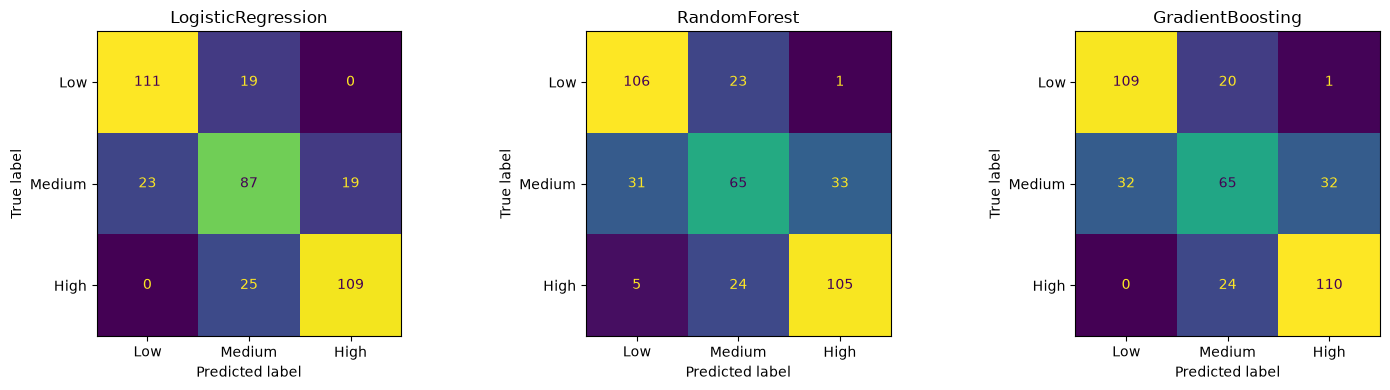

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pipe) in zip(axes, pipelines.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=RISK_ORDER).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

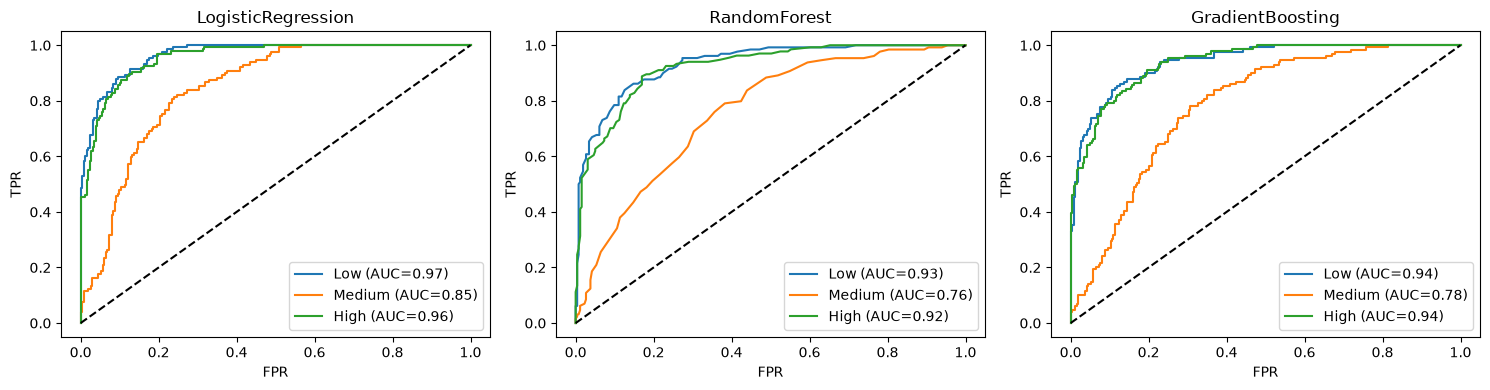

In [9]:
y_bin = label_binarize(y_test, classes=[0, 1, 2])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pipe) in zip(axes, pipelines.items()):
    proba = pipe.predict_proba(X_test)
    for i, risk in enumerate(RISK_ORDER):
        fpr, tpr, _ = roc_curve(y_bin[:, i], proba[:, i])
        ax.plot(fpr, tpr, label=f"{risk} (AUC={roc_auc_score(y_bin[:, i], proba[:, i]):.2f})")
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_title(name)
    ax.set_xlabel("FPR")
    ax.set_ylabel("TPR")
    ax.legend()
plt.tight_layout()
plt.show()

In [10]:
test = metrics[metrics.split == "test"].set_index("model").drop(columns="split")
test.sort_values("f1", ascending=False).round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
LogisticRegression,0.781,0.781,0.781,0.781,0.923
GradientBoosting,0.723,0.713,0.721,0.715,0.888
RandomForest,0.702,0.694,0.701,0.696,0.871


In [ ]:
dag_pipelines, dag_results = train_models(X_train, X_test, y_train, y_test)
for name in pipelines:
    assert abs(dag_results[name]["f1"] - test.loc[name, "f1"]) < 1e-9, name
print("train_models() == notebook results")

train_models() == notebook results
